# Issue #16: Time-Series Charging-Demand Analysis and Forecasting

**Input:** `acn_structured_sessions.csv` (Issue #3, full collection: 31,424 sessions), `collection_log.csv` (Issue #2), `acn_clean_sessions.csv` (Issue #9, used only to reconcile)
**Outputs:**
- `time_series_daily.csv` — prepared daily time-series dataset (one row per calendar day, gaps and regimes labelled)
- `time_series_hourly.csv` — hourly arrivals and plugged-in vehicles (intraday analysis)
- `ts_tables/` and `ts_figures/` — analysis tables and time-series visualizations
- `ts_backtest_i16.csv` — rolling-origin comparison of forecasting approaches
- `models/sarimax_daily_sessions_i16.joblib` — trained forecasting model
- `forecast_holdout_i16.csv` — actual vs. forecast on held-out weeks (input to Issue #17)
- `forecast_daily_i16.csv` — future daily demand forecasts with prediction intervals
- `time_series_findings.md` — documented time-series findings (generated from the data)

**Why the full collection and not `acn_clean_sessions.csv`.** Issue #9 cleaned the 14,400-session partial download (Apr–Nov 2018, 218 days). The completed collection (`dataset updated` commit) covers **Apr 2018 – Sep 2021**, but Issue #9 has not been re-run on it, so `acn_clean_sessions.csv` still holds the partial window. A time-series analysis needs the longest clean history it can get (seasonality, regime changes, a forecast origin that is not in the middle of a policy change), so this notebook applies **the same Issue #9 rules** to the full file and then checks that, on the overlapping window, it reproduces `acn_clean_sessions.csv` day by day (§1.2).

**Rules for this notebook**
- Time order is never broken: no shuffling, and every forecast uses only data before its origin.
- Days with no records are classified (real zero demand vs. period with no data) before anything is modelled.
- Models are fitted **within one demand regime** at a time; a series is never fitted across a structural break.
- Every number in the findings is computed in this notebook.

## 1. Time-Series Dataset Preparation

### 1.0 Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from IPython.display import Markdown, display
from pandas.tseries.holiday import USFederalHolidayCalendar

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

def find_root():
    # Works when run from the repository root or from notebooks/
    cwd = pathlib.Path.cwd()
    for p in [cwd, cwd.parent]:
        if (p / 'acn_structured_sessions.csv').exists():
            return p
    raise FileNotFoundError('acn_structured_sessions.csv not found in . or ..')

ROOT = find_root()
FIG_DIR, TAB_DIR, MODEL_DIR = ROOT / 'ts_figures', ROOT / 'ts_tables', ROOT / 'models'
for p in (FIG_DIR, TAB_DIR, MODEL_DIR):
    p.mkdir(exist_ok=True)

TS_FORMAT = '%a, %d %b %Y %H:%M:%S GMT'
LOCAL_TZ = 'America/Los_Angeles'

# Issue #9 thresholds, reused unchanged so both datasets follow the same rules
MIN_KWH, MAX_KWH = 0.1, 100.0     # guard
MIN_CONNECT_MIN = 1.0             # guard
MAX_CONNECT_H = 72.0              # ACTIVE (excluded from counts, kept for occupancy)

# Chart styling: one recessive grid, categorical colours in a fixed order (regime identity)
INK, INK2, GRID, NEUTRAL = '#0b0b0b', '#52514e', '#e4e3df', '#b9b8b3'
SERIES = '#2a78d6'
REGIME_COLORS = {'free': '#2a78d6', 'paid': '#eb6834', 'covid': '#1baf7a',
                 'recovery': '#eda100', 'nodata': NEUTRAL}
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.6, 'axes.edgecolor': '#c3c2b7', 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlesize': 11,
    'axes.titlelocation': 'left', 'axes.labelcolor': INK2, 'xtick.color': INK2,
    'ytick.color': INK2, 'text.color': INK, 'lines.linewidth': 1.6, 'legend.frameon': False,
    'axes.axisbelow': True,
})

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()

def hhmm(hours):
    # 13.75 -> '13:45' (time of day given in hours)
    m = int(round(hours * 60))
    return f'{m // 60 % 24:02d}:{m % 60:02d}'

def save_table(frame, name, index=True):
    frame.to_csv(TAB_DIR / f'{name}.csv', index=index)
    return frame

print('Repository root:', ROOT)

Repository root: D:\AA sem 7\BA_proj\EV-Charging-Demand-Analytics


### 1.1 Load the full collection and apply the Issue #9 rules

Same parsing (UTC → `America/Los_Angeles`), same guards and the same ACTIVE rule (connections over 72 h). Two session sets come out of this step:

- `sessions` — the demand events used for counts and energy (> 72 h connections excluded, as in Issue #9);
- `occ_sessions` — also includes the > 72 h connections, because those vehicles did occupy a charger (Issue #9 asks for them to be added back for occupancy analysis).

Issue #9's *outside contiguous coverage* rule is **not** applied: here gaps are handled explicitly in the time series (§1.5) instead of by deleting sessions.

In [2]:
raw = pd.read_csv(ROOT / 'acn_structured_sessions.csv',
                  dtype={'siteID': str, 'clusterID': str, 'userID': str})
n_raw = len(raw)

for c in ['connectionTime', 'disconnectTime', 'doneChargingTime']:
    raw[c] = pd.to_datetime(raw[c], format=TS_FORMAT, errors='coerce', utc=True)
raw['kWhDelivered'] = pd.to_numeric(raw['kWhDelivered'], errors='coerce')
raw['connected_h'] = (raw['disconnectTime'] - raw['connectionTime']).dt.total_seconds() / 3600
raw['start_local'] = raw['connectionTime'].dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
raw['end_local'] = raw['disconnectTime'].dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
raw['date'] = raw['start_local'].dt.normalize()

rules = {
    'duplicate _id': ('guard', raw['_id'].duplicated()),
    'duplicate sessionID': ('guard', raw['sessionID'].duplicated()),
    'duplicate station+connectionTime': ('guard', raw.duplicated(['stationID', 'connectionTime'])),
    'unparseable connect/disconnect time': ('guard', raw['connectionTime'].isna() | raw['disconnectTime'].isna()),
    'disconnect not after connect': ('guard', raw['disconnectTime'] <= raw['connectionTime']),
    f'kWhDelivered outside [{MIN_KWH}, {MAX_KWH}]': ('guard', ~raw['kWhDelivered'].between(MIN_KWH, MAX_KWH)),
    f'connected < {MIN_CONNECT_MIN:.0f} min': ('guard', raw['connected_h'] * 60 < MIN_CONNECT_MIN),
    f'connected > {MAX_CONNECT_H:.0f} h': ('ACTIVE', raw['connected_h'] > MAX_CONNECT_H),
}
cleaning = pd.DataFrame([(k, kind, int(m.sum())) for k, (kind, m) in rules.items()],
                        columns=['rule', 'kind', 'rows_flagged'])
guard_fail = np.logical_or.reduce([m for kind, m in rules.values() if kind == 'guard'])
long_conn = rules[f'connected > {MAX_CONNECT_H:.0f} h'][1]

occ_sessions = raw[~guard_fail].copy()
sessions = raw[~guard_fail & ~long_conn].sort_values('connectionTime').reset_index(drop=True)
assert len(sessions) + int((guard_fail | long_conn).sum()) == n_raw

save_table(cleaning, '01_cleaning_rules', index=False)
print(f'Loaded {n_raw:,} sessions | kept for demand: {len(sessions):,} | '
      f'kept for occupancy: {len(occ_sessions):,} | stations: {sessions.stationID.nunique()}')
print('Local date range:', sessions['date'].min().date(), '->', sessions['date'].max().date())
cleaning

Loaded 31,424 sessions | kept for demand: 31,387 | kept for occupancy: 31,424 | stations: 55
Local date range: 2018-04-25 -> 2021-09-13


,rule,kind,rows_flagged
0,duplicate _id,guard,0
1,duplicate sessionID,guard,0
2,duplicate station+connectionTime,guard,0
3,unparseable connect/disconnect time,guard,0
4,disconnect not after connect,guard,0
5,"kWhDelivered outside [0.1, 100.0]",guard,0
6,connected < 1 min,guard,0
7,connected > 72 h,ACTIVE,37


### 1.2 Reconciliation with `acn_clean_sessions.csv` (Issue #9)

On the window covered by the Issue #9 file, the daily counts produced here should be identical. Any difference must be explainable.

In [3]:
clean9 = pd.read_csv(ROOT / 'acn_clean_sessions.csv', usecols=['sessionID', 'connectionTime', 'date'],
                     parse_dates=['date'])
w0, w1 = clean9['date'].min(), clean9['date'].max()
mine = sessions.loc[sessions['date'].between(w0, w1)]
recon = pd.DataFrame({'this_notebook': mine.groupby('date').size(),
                      'acn_clean_sessions': clean9.groupby('date').size()}).fillna(0).astype(int)
recon['difference'] = recon['this_notebook'] - recon['acn_clean_sessions']
mismatch = recon[recon['difference'] != 0]
save_table(recon, '02_reconciliation_issue9')

only_here = set(mine['sessionID']) - set(clean9['sessionID'])
only_there = set(clean9['sessionID']) - set(mine['sessionID'])
last_clean_local = (pd.to_datetime(clean9['connectionTime'], utc=True).max()
                    .tz_convert(LOCAL_TZ).tz_localize(None))
print(f'Window {w0.date()} -> {w1.date()}: {len(recon)} days, identical on {int((recon.difference == 0).sum())}')
print(f'Sessions only in this notebook: {len(only_here)} | only in acn_clean_sessions: {len(only_there)}')
print('Last session in the Issue #9 file (local):', last_clean_local)
mismatch

Window 2018-04-25 -> 2018-11-28: 218 days, identical on 217
Sessions only in this notebook: 21 | only in acn_clean_sessions: 0
Last session in the Issue #9 file (local): 2018-11-28 09:53:08


,this_notebook,acn_clean_sessions,difference
date,,,
2018-11-28,54,33,21


In [4]:
late = mine[mine['sessionID'].isin(only_here)]
explained = bool(len(only_there) == 0 and (late['start_local'] > last_clean_local).all())
display(Markdown(
    f"**Result.** {int((recon.difference == 0).sum())} of {len(recon)} days match exactly. "
    + (f"The {len(only_here)} extra sessions all start after the last session of the partial download "
       f"({last_clean_local:%Y-%m-%d %H:%M} local) — that download stopped part-way through its last day. "
       "No session in the Issue #9 file is missing here, so the cleaning rules are reproduced exactly."
       if explained else "Differences remain that are not explained by the partial last day; inspect `mismatch`.")))
assert explained

**Result.** 217 of 218 days match exactly. The 21 extra sessions all start after the last session of the partial download (2018-11-28 09:53 local) — that download stopped part-way through its last day. No session in the Issue #9 file is missing here, so the cleaning rules are reproduced exactly.

### 1.3 Demand variable and time granularity

| Candidate | Definition | Role here |
|---|---|---|
| **`session_count`** | plug-in events per local calendar day | **Primary demand variable** — same target as Issue #13, directly actionable for charger allocation, fully observed for every session |
| `total_kWh` | energy delivered per day | Secondary (energy / tariff view); checked for redundancy below |
| `peak_occupancy` | most vehicles plugged in at the same time during the day (15-min resolution) | Capacity variable — what the chargers actually have to absorb |

| Granularity | Used for | Why |
|---|---|---|
| **Daily** | trend, weekly pattern, anomalies, **forecasting** | robust counts, matches the Issue #13 prediction unit and operational planning (next days/weeks) |
| Hourly / 15-min | intraday arrivals and plugged-in profile, peak hours | capacity is an intraday question; hourly counts are too sparse (many zero nights) to forecast directly |
| Weekly | regime detection, long-run trend | removes the weekday cycle so level shifts stand out |

**Plugged-in vehicles** are computed on a 15-minute grid in local time: a vehicle counts at instant *t* if `connection ≤ t < disconnection`. Local wall-clock time is used throughout; the daylight-saving switch adds or removes one night-time hour twice a year, when almost no vehicles arrive.

In [5]:
start, end = sessions['date'].min(), sessions['date'].max()
calendar = pd.date_range(start, end, freq='D', name='date')

# Plugged-in vehicles on a 15-minute grid (includes > 72 h connections)
grid = pd.date_range(start, end + pd.Timedelta(days=1), freq='15min', inclusive='left')
a = np.searchsorted(grid.values, occ_sessions['start_local'].values.astype('datetime64[ns]'), side='left')
b = np.searchsorted(grid.values, occ_sessions['end_local'].values.astype('datetime64[ns]'), side='left')
delta = np.zeros(len(grid) + 1)
np.add.at(delta, a, 1)
np.add.at(delta, b, -1)
occupancy = pd.Series(np.cumsum(delta)[:-1], index=grid, name='plugged_in')

g = sessions.groupby('date')
daily = pd.DataFrame(index=calendar)
daily['session_count'] = g.size().reindex(calendar, fill_value=0)
daily['total_kWh'] = g['kWhDelivered'].sum().reindex(calendar, fill_value=0.0).round(3)
daily['avg_kWh_per_session'] = (daily['total_kWh'] / daily['session_count'].replace(0, np.nan)).round(3)
daily['plugged_in_hours'] = g['connected_h'].sum().reindex(calendar, fill_value=0.0).round(3)
daily['active_stations'] = g['stationID'].nunique().reindex(calendar, fill_value=0)
daily['peak_occupancy'] = occupancy.resample('D').max().reindex(calendar).astype(int)
daily['dayofweek'] = daily.index.dayofweek
daily['is_weekend'] = (daily['dayofweek'] >= 5).astype(int)
daily['month'] = daily.index.month
daily['year'] = daily.index.year

# Hourly table: arrivals by arrival hour, plugged-in vehicles averaged within the hour
hours = pd.date_range(start, end + pd.Timedelta(hours=23), freq='h', name='datetime_local')
hg = sessions.groupby(sessions['start_local'].dt.floor('h'))
hourly = pd.DataFrame(index=hours)
hourly['arrivals'] = hg.size().reindex(hours, fill_value=0)
hourly['kWh_of_arrivals'] = hg['kWhDelivered'].sum().reindex(hours, fill_value=0.0).round(3)
hourly['mean_plugged_in'] = occupancy.resample('h').mean().reindex(hours).round(3)
hourly['max_plugged_in'] = occupancy.resample('h').max().reindex(hours).astype(int)

assert daily.index.is_monotonic_increasing and daily.index.is_unique
assert hourly.index.is_monotonic_increasing and hourly.index.is_unique
assert daily['session_count'].sum() == len(sessions) == hourly['arrivals'].sum()

r = daily.loc[daily.session_count > 0, ['session_count', 'total_kWh', 'peak_occupancy']].corr().round(3)
print(f'Daily rows: {len(daily)} | hourly rows: {len(hourly):,}')
print('Correlation between candidate daily demand variables (days with sessions):')
r

Daily rows: 1238 | hourly rows: 29,712
Correlation between candidate daily demand variables (days with sessions):


,session_count,total_kWh,peak_occupancy
session_count,1.000,0.967,0.952
total_kWh,0.967,1.000,0.907
peak_occupancy,0.952,0.907,1.000


`total_kWh` moves almost one-for-one with `session_count`, so it carries little extra information for a daily demand model; it is kept in the dataset and converted from the session forecast where needed (§3.5). `peak_occupancy` is also strongly tied to the session count and is used to translate forecasts into charger requirements.

### 1.4 Chronological order and missing time periods

The series was re-indexed onto a complete daily calendar above, so a missing period appears as a run of zero-session days. Zero days are of two kinds and must not be mixed: real zero demand (closures, lockdown) and periods where the source simply has no records. The Issue #2 collection log shows whether each weekly window was queried and how many sessions it returned.

In [6]:
is_zero = daily['session_count'].eq(0)
run_id = (is_zero != is_zero.shift()).cumsum()
zero_runs = (daily[is_zero].groupby(run_id[is_zero])
             .apply(lambda f: pd.Series({'start': f.index.min().date(), 'end': f.index.max().date(), 'days': len(f)}))
             .reset_index(drop=True).sort_values('days', ascending=False))

log = pd.read_csv(ROOT / 'collection_log.csv')
log['week_start'] = pd.to_datetime(log['week_start'], format=TS_FORMAT)
print(f'Collection log: {len(log)} weekly windows queried, {log.sessions.sum():,} sessions, '
      f'{int((log.sessions == 0).sum())} windows returned 0 sessions')
print(f'Zero-session days: {int(is_zero.sum())} in {len(zero_runs)} runs')
save_table(zero_runs, '03_zero_session_runs', index=False)
zero_runs.head(8)

Collection log: 178 weekly windows queried, 31,424 sessions, 14 windows returned 0 sessions
Zero-session days: 154 in 28 runs


,start,end,days
26,2020-08-04,2020-11-17,106
16,2020-05-21,2020-05-25,5
12,2020-04-30,2020-05-03,4
13,2020-05-05,2020-05-08,4
7,2020-04-15,2020-04-17,3
22,2020-06-14,2020-06-16,3
23,2020-06-23,2020-06-24,2
18,2020-05-30,2020-05-31,2


In [7]:
NO_DATA_MIN_DAYS = 14   # a zero run this long at a site that had demand on both sides is treated as missing data
gap = zero_runs.iloc[0]
assert gap['days'] >= NO_DATA_MIN_DAYS and (zero_runs['days'].iloc[1:] < NO_DATA_MIN_DAYS).all()
GAP_START, GAP_END = pd.Timestamp(gap['start']), pd.Timestamp(gap['end'])

log_in_gap = log[(log.week_start >= GAP_START - pd.Timedelta(days=6)) & (log.week_start <= GAP_END)]
before = daily.loc[GAP_START - pd.Timedelta(days=28):GAP_START - pd.Timedelta(days=1), 'session_count'].mean()
after = daily.loc[GAP_END + pd.Timedelta(days=1):GAP_END + pd.Timedelta(days=28), 'session_count'].mean()
print(f'Longest zero run: {GAP_START.date()} -> {GAP_END.date()} ({gap.days} days)')
print(f'Weekly windows overlapping it in the collection log: {len(log_in_gap)}, sessions returned: {log_in_gap.sessions.sum()}')
print(f'Mean sessions/day in the 4 weeks before: {before:.1f} | 4 weeks after: {after:.1f}')

Longest zero run: 2020-08-04 -> 2020-11-17 (106 days)
Weekly windows overlapping it in the collection log: 16, sessions returned: 29
Mean sessions/day in the 4 weeks before: 2.1 | 4 weeks after: 6.4


**Decision.** The long run of zero days was queried successfully (the collection log returns 0 sessions for every window in it), so it is not a collection failure — but the site had demand immediately before and after, and no other zero run is longer than a few days. Whether chargers were shut or records were not kept cannot be told from the data, so this period is labelled **`nodata`** and set to missing (`observed = 0`) rather than read as zero demand. All shorter zero runs (holiday weeks, the lockdown) are real zero demand and stay at 0.

### 1.5 Demand regimes (structural breaks)

The level of demand changes abruptly several times. Two of the changes are documented events: Caltech began charging for sessions on **1 Nov 2018** (Issue #10 policy-regime analysis), and campus activity stopped with the **COVID-19 shutdown in March 2020**. Rather than assume the boundaries, the weekly series is segmented by exact least-squares optimal partitioning (changes in mean of `log(1 + weekly sessions)`, full weeks only, the no-data period removed); segments are added while each one still reduces the cost by at least 20%.

In [8]:
weekly = daily['session_count'].resample('W-MON', label='left', closed='left').sum()
wk_days = daily['session_count'].resample('W-MON', label='left', closed='left').size()
weekly = weekly[wk_days == 7]
in_gap = (weekly.index + pd.Timedelta(days=6) >= GAP_START) & (weekly.index <= GAP_END)
wk = np.log1p(weekly[~in_gap])

def optimal_partition(x, k, min_len=4):
    # Exact dynamic programme: k segments minimising the within-segment sum of squares
    n = len(x)
    cs, cs2 = np.r_[0, np.cumsum(x)], np.r_[0, np.cumsum(x ** 2)]
    cost = lambda i, j: (cs2[j] - cs2[i]) - (cs[j] - cs[i]) ** 2 / (j - i)
    C = np.full((k + 1, n + 1), np.inf); P = np.zeros((k + 1, n + 1), dtype=int); C[0, 0] = 0
    for kk in range(1, k + 1):
        for j in range(kk * min_len, n + 1):
            C[kk, j], P[kk, j] = min((C[kk - 1, i] + cost(i, j), i)
                                     for i in range((kk - 1) * min_len, j - min_len + 1))
    bounds, j = [], n
    for kk in range(k, 0, -1):
        j = P[kk, j]; bounds.append(j)
    return sorted(bounds)[1:], C[k, n]

costs, breaks = {}, {}
for k in range(1, 8):
    breaks[k], costs[k] = optimal_partition(wk.values, k)
K = 1
while K < 7 and costs[K + 1] <= 0.8 * costs[K]:
    K += 1
detected = [wk.index[i] for i in breaks[K]]
cp_table = pd.DataFrame({'segments': list(costs), 'cost': np.round(list(costs.values()), 2),
                         'break_weeks': [', '.join(str(wk.index[i].date()) for i in breaks[k]) for k in costs]})
save_table(cp_table, '04_changepoint_search', index=False)
print('Segments selected:', K, '| detected break weeks:', [d.date() for d in detected])
cp_table

Segments selected: 5 | detected break weeks: [datetime.date(2018, 11, 19), datetime.date(2020, 3, 16), datetime.date(2020, 11, 23), datetime.date(2021, 3, 15)]


,segments,cost,break_weeks
0,1,244.95,
1,2,99.59,2020-03-16
2,3,39.01,"2020-03-16, 2020-11-23"
3,4,23.49,"2018-11-19, 2020-03-16, 2020-11-23"
4,5,17.38,"2018-11-19, 2020-03-16, 2020-11-23, 2021-03-15"
5,6,14.89,"2018-11-19, 2020-03-16, 2020-06-15, 2020-11-23..."
6,7,13.53,"2018-11-19, 2020-03-16, 2020-06-15, 2020-11-23..."


In [9]:
REGIMES = pd.DataFrame([
    ('free',     'Free charging',             '2018-04-25', '2018-10-31', 'documented: paid charging from 1 Nov 2018'),
    ('paid',     'Paid charging, pre-COVID',  '2018-11-01', '2020-03-15', 'documented price change; break detected at the COVID shutdown'),
    ('covid',    'COVID-19 shutdown',         '2020-03-16', str((GAP_START - pd.Timedelta(days=1)).date()), 'detected break'),
    ('nodata',   'No records',                str(GAP_START.date()), str(GAP_END.date()), 'zero run in §1.4'),
    ('recovery', 'Post-COVID recovery',       str((GAP_END + pd.Timedelta(days=1)).date()), str(end.date()), 'demand resumes after the gap'),
], columns=['regime', 'label', 'start', 'end', 'basis'])
REGIMES[['start', 'end']] = REGIMES[['start', 'end']].apply(pd.to_datetime)
REGIMES = REGIMES.set_index('regime')
assert REGIMES['start'].iloc[0] == start and REGIMES['end'].iloc[-1] == end
assert ((REGIMES['start'].iloc[1:].values - REGIMES['end'].iloc[:-1].values) == np.timedelta64(1, 'D')).all()

daily['regime'] = None
for name, row in REGIMES.iterrows():
    daily.loc[row.start:row.end, 'regime'] = name
daily['observed'] = (daily['regime'] != 'nodata').astype(int)
daily.loc[daily['observed'] == 0, ['session_count', 'total_kWh', 'plugged_in_hours', 'peak_occupancy']] = np.nan
hourly['regime'] = daily['regime'].reindex(hourly.index.normalize()).values
hourly['observed'] = daily['observed'].reindex(hourly.index.normalize()).values
hourly.loc[hourly['observed'] == 0, ['arrivals', 'kWh_of_arrivals', 'mean_plugged_in', 'max_plugged_in']] = np.nan

# How far is each detected break from the nearest regime boundary?
bounds = list(REGIMES['start'].iloc[1:])
cp_vs = pd.DataFrame({'detected_week': detected,
                      'nearest_regime_start': [min(bounds, key=lambda b: abs(b - d)) for d in detected]})
cp_vs['days_apart'] = (cp_vs['detected_week'] - cp_vs['nearest_regime_start']).dt.days
save_table(REGIMES.reset_index(), '05_regimes', index=False)
display(REGIMES)
cp_vs

,label,start,end,basis
regime,,,,
free,Free charging,2018-04-25,2018-10-31,documented: paid charging from 1 Nov 2018
paid,"Paid charging, pre-COVID",2018-11-01,2020-03-15,documented price change; break detected at the...
covid,COVID-19 shutdown,2020-03-16,2020-08-03,detected break
nodata,No records,2020-08-04,2020-11-17,zero run in §1.4
recovery,Post-COVID recovery,2020-11-18,2021-09-13,demand resumes after the gap


,detected_week,nearest_regime_start,days_apart
0,2018-11-19,2018-11-01,18
1,2020-03-16,2020-03-16,0
2,2020-11-23,2020-11-18,5
3,2021-03-15,2020-11-18,117


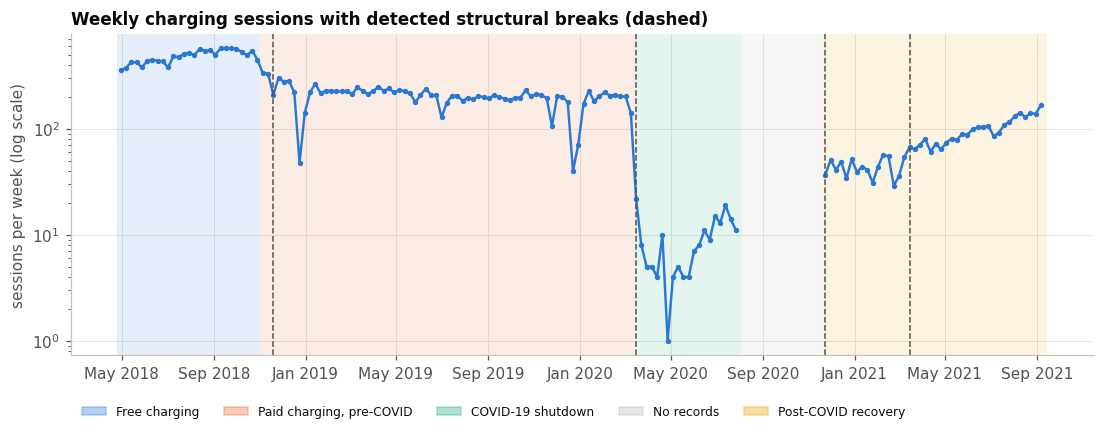

In [10]:
fig, ax = plt.subplots(figsize=(12, 3.8))
for name, row in REGIMES.iterrows():
    ax.axvspan(row.start, row.end + pd.Timedelta(days=1), color=REGIME_COLORS[name], alpha=0.12, lw=0)
ax.plot(weekly.index, weekly.where(~in_gap), color=SERIES, lw=1.6, marker='o', ms=2.5)   # line breaks at the gap
for d in detected:
    ax.axvline(d, color=INK2, lw=1, ls='--')
ax.set_yscale('log')
ax.set_ylabel('sessions per week (log scale)')
ax.set_title('Weekly charging sessions with detected structural breaks (dashed)')
ax.legend(handles=[Patch(color=REGIME_COLORS[n], alpha=0.35, label=REGIMES.loc[n, 'label']) for n in REGIMES.index],
          ncol=5, loc='upper left', bbox_to_anchor=(0, -0.12), fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
save_fig(fig, 'T01_weekly_demand_regime_breaks')

The detected breaks coincide with the regime boundaries: the paid-charging break is found a few weeks after 1 Nov 2018 because drivers adjusted over November, and the shutdown break falls in the week of 16 March 2020. A further break inside the recovery marks where growth accelerated; it is a change in trend within one regime, not a new regime, and is analysed in §2.1.

### 1.6 Campus closure calendar

Holidays are the largest day-level effect in this kind of data, and a forecaster needs to know them in advance. Caltech does not observe every US federal holiday, so the closure list is derived from the data: each candidate day is compared with the median of the same weekday in the surrounding ±3 weeks (other candidate days excluded). A holiday counts as a **campus closure** when its median ratio across years is below 0.6. Candidates: all US federal holidays, the day after Thanksgiving, and 24–31 December.

In [11]:
CLOSURE_RATIO = 0.6

def candidate_days(first, last):
    fed = USFederalHolidayCalendar().holidays(first, last, return_name=True)
    out = fed.copy()
    for d in fed[fed.str.contains('Thanksgiving')].index:
        out[d + pd.Timedelta(days=1)] = 'Day after Thanksgiving'
    for yr in range(first.year, last.year + 1):
        for d in pd.date_range(f'{yr}-12-24', f'{yr}-12-31'):
            if d not in out.index or out[d] != 'Christmas Day':
                out[d] = 'Winter break (24-31 Dec)'
    return out.sort_index()

cand = candidate_days(start, end)
obs = daily.loc[daily['regime'].isin(['free', 'paid', 'recovery']), 'session_count']
base_pool = obs[~obs.index.isin(cand.index)]
rows = []
for d, name in cand.items():
    if d not in obs.index:
        continue
    near = base_pool[(base_pool.index.dayofweek == d.dayofweek) & (abs((base_pool.index - d).days) <= 21)]
    if len(near) >= 2 and near.median() > 0:
        rows.append((d.date(), name, daily.at[d, 'regime'], int(obs[d]), float(near.median()), obs[d] / near.median()))
hol_check = pd.DataFrame(rows, columns=['date', 'holiday', 'regime', 'sessions', 'same_weekday_median', 'ratio'])
by_name = (hol_check.groupby('holiday')['ratio'].agg(['median', 'min', 'max', 'count'])
           .round(2).sort_values('median'))
by_name['campus_closure'] = by_name['median'] < CLOSURE_RATIO
CLOSURE_NAMES = set(by_name.index[by_name['campus_closure']])

def closure_calendar(first, last):
    c = candidate_days(first, last)
    return c[c.isin(CLOSURE_NAMES)]

closures = closure_calendar(start, end)
daily['holiday_name'] = cand.reindex(daily.index).values
daily['campus_closure'] = daily.index.isin(closures.index).astype(int)
save_table(hol_check.round(3), '06_holiday_effects', index=False)
save_table(by_name, '06b_closure_rule_by_holiday')
print('Not treated as closures:', sorted(set(by_name.index) - CLOSURE_NAMES))
by_name

Not treated as closures: ['Columbus Day', 'Juneteenth National Independence Day', 'Veterans Day']


,median,min,max,count,campus_closure
holiday,,,,,
Christmas Day,0.00,0.00,0.10,3,True
New Year's Day,0.17,0.14,1.00,3,True
Thanksgiving Day,0.17,0.03,1.00,3,True
Day after Thanksgiving,0.18,0.13,0.38,3,True
Memorial Day,0.30,0.28,0.50,3,True
Independence Day,0.31,0.16,0.45,3,True
Labor Day,0.38,0.35,0.40,3,True
Winter break (24-31 Dec),0.40,0.03,2.00,21,True
Washington's Birthday,0.52,0.36,1.23,3,True


### 1.7 Prepared time-series datasets

In [12]:
daily_out = daily.reset_index()
daily_out['date'] = daily_out['date'].dt.date
hourly_out = hourly.reset_index()
hourly_out.insert(1, 'date', hourly_out['datetime_local'].dt.date)
hourly_out.insert(2, 'hour', hourly_out['datetime_local'].dt.hour)

# Validation of the prepared datasets
assert daily_out['date'].is_unique and len(daily_out) == (end - start).days + 1
assert daily.loc[daily.observed == 1, 'session_count'].notna().all()
assert daily.loc[daily.observed == 0, 'session_count'].isna().all()
assert int(daily['session_count'].sum()) == len(sessions)       # gap days had no sessions
assert (daily['peak_occupancy'].dropna() <= occ_sessions['stationID'].nunique()).all()
assert hourly['arrivals'].sum() == daily['session_count'].sum()

daily_out.to_csv(ROOT / 'time_series_daily.csv', index=False)
hourly_out.to_csv(ROOT / 'time_series_hourly.csv', index=False)
print('Saved time_series_daily.csv :', daily_out.shape)
print('Saved time_series_hourly.csv:', hourly_out.shape)
print('Observed days by regime:')
print(daily.groupby('regime', sort=False)['observed'].agg(days='size', observed='sum').to_string())
daily_out.head()

Saved time_series_daily.csv : (1238, 15)
Saved time_series_hourly.csv: (29712, 9)
Observed days by regime:
          days  observed
regime                  
free       190       190
paid       501       501
covid      141       141
nodata     106         0
recovery   300       300


,date,session_count,total_kWh,avg_kWh_per_session,plugged_in_hours,active_stations,peak_occupancy,dayofweek,is_weekend,month,year,regime,observed,holiday_name,campus_closure
0,2018-04-25,59.0,441.601,7.485,339.082,36,32.0,2,0,4,2018,free,1,NaN,0
1,2018-04-26,47.0,338.813,7.209,302.922,37,32.0,3,0,4,2018,free,1,NaN,0
2,2018-04-27,51.0,572.427,11.224,393.742,34,29.0,4,0,4,2018,free,1,NaN,0
3,2018-04-28,30.0,341.136,11.371,128.438,16,15.0,5,1,4,2018,free,1,NaN,0
4,2018-04-29,28.0,264.711,9.454,100.309,17,11.0,6,1,4,2018,free,1,NaN,0


## 2. Time-Based Analysis

Unless stated otherwise, statistics are computed **per regime**, because pooling a free-charging day with a lockdown day describes neither. "Typical weekday" figures exclude campus closures.

### 2.1 Overall demand trend

In [13]:
MODEL_REGIMES = ['free', 'paid', 'recovery']        # regimes with normal campus operation
d_obs = daily[daily.observed == 1]
typical = d_obs[d_obs.campus_closure == 0]

def regime_summary(name):
    dr, tr = d_obs[d_obs.regime == name], typical[typical.regime == name]
    wd, we = tr[tr.is_weekend == 0], tr[tr.is_weekend == 1]
    st = occ_sessions[occ_sessions['date'].between(REGIMES.at[name, 'start'], REGIMES.at[name, 'end'])]
    n_st = st['stationID'].nunique()
    return pd.Series({
        'start': REGIMES.at[name, 'start'].date(), 'end': REGIMES.at[name, 'end'].date(),
        'observed_days': len(dr), 'sessions': int(dr.session_count.sum()),
        'mean_sessions_per_day': dr.session_count.mean(),
        'typical_weekday_sessions': wd.session_count.mean(), 'typical_weekend_sessions': we.session_count.mean(),
        'weekend_to_weekday_ratio': we.session_count.mean() / wd.session_count.mean(),
        'mean_kWh_per_day': dr.total_kWh.mean(), 'kWh_per_session': dr.total_kWh.sum() / dr.session_count.sum(),
        'stations_used': n_st, 'mean_weekday_peak_occupancy': wd.peak_occupancy.mean(),
        'max_peak_occupancy': dr.peak_occupancy.max(),
    })

reg_sum = pd.DataFrame({n: regime_summary(n) for n in ['free', 'paid', 'covid', 'recovery']}).T
save_table(reg_sum, '07_regime_summary')
reg_sum.round(2)

,start,end,observed_days,sessions,mean_sessions_per_day,typical_weekday_sessions,typical_weekend_sessions,weekend_to_weekday_ratio,mean_kWh_per_day,kWh_per_session,stations_used,mean_weekday_peak_occupancy,max_peak_occupancy
free,2018-04-25,2018-10-31,190,13096,68.926316,79.75188,44.648148,0.559838,619.091995,8.981939,54,42.345865,51.0
paid,2018-11-01,2020-03-15,501,14802,29.54491,38.993976,11.607143,0.297665,259.878273,8.796042,54,26.993976,42.0
covid,2020-03-16,2020-08-03,141,183,1.297872,1.353535,1.2,0.886567,14.013915,10.797607,34,1.040404,7.0
recovery,2020-11-18,2021-09-13,300,3306,11.02,12.66,8.059524,0.636613,135.139973,12.263155,45,5.565,19.0


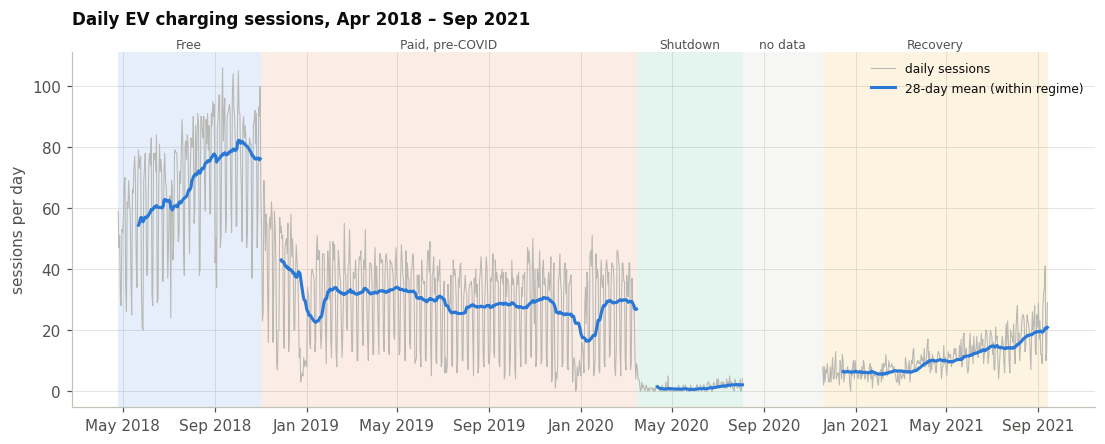

In [14]:
roll = d_obs['session_count'].rolling('28D', min_periods=21).mean()
roll[daily.loc[roll.index, 'regime'].ne(daily.loc[roll.index, 'regime'].shift(27))] = np.nan  # no window across a break

fig, ax = plt.subplots(figsize=(12, 4.2))
for name, row in REGIMES.iterrows():
    ax.axvspan(row.start, row.end + pd.Timedelta(days=1), color=REGIME_COLORS[name], alpha=0.12, lw=0)
    short = {'free': 'Free', 'paid': 'Paid, pre-COVID', 'covid': 'Shutdown', 'nodata': 'no data', 'recovery': 'Recovery'}[name]
    ax.text(row.start + (row.end - row.start) / 2, 1.0, short, transform=ax.get_xaxis_transform(),
            ha='center', va='bottom', fontsize=8, color=INK2)
ax.plot(daily.index, daily['session_count'], color=NEUTRAL, lw=0.7, label='daily sessions')
ax.plot(roll.index, roll, color=SERIES, lw=2, label='28-day mean (within regime)')
ax.set_ylabel('sessions per day')
ax.set_title('Daily EV charging sessions, Apr 2018 – Sep 2021', pad=18)
ax.legend(loc='upper right', fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
save_fig(fig, 'T02_daily_demand_trend')

Recovery from 2021-03-15: weekly sessions grew 3.6% per week (doubling every 19.8 weeks, 26 full weeks)
Paid regime (2019 onwards): typical weekday trend -4.6 sessions/day per year


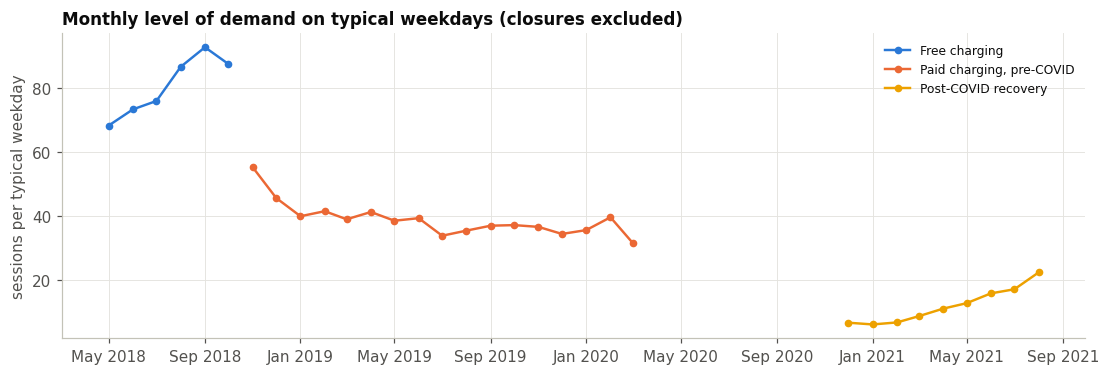

month,2018-05-01,2018-06-01,2018-07-01,2018-08-01,2018-09-01,2018-10-01,2018-11-01,2018-12-01,2019-01-01,2019-02-01,2019-03-01,2019-04-01,2019-05-01,2019-06-01,2019-07-01,2019-08-01,2019-09-01,2019-10-01,2019-11-01,2019-12-01,2020-01-01,2020-02-01,2020-03-01,2020-04-01,2020-05-01,2020-06-01,2020-07-01,2020-12-01,2021-01-01,2021-02-01,2021-03-01,2021-04-01,2021-05-01,2021-06-01,2021-07-01,2021-08-01
regime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
covid,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.1,0.5,0.6,1.4,2.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
free,68.2,73.3,75.9,86.6,92.7,87.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
paid,NaN,NaN,NaN,NaN,NaN,NaN,55.2,45.6,39.9,41.5,39.0,41.2,38.5,39.3,33.8,35.4,37.0,37.1,36.6,34.4,35.6,39.6,31.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
recovery,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.6,6.1,6.7,8.7,11.0,12.8,15.8,17.1,22.4


In [15]:
m = typical[typical.is_weekend == 0].groupby([pd.Grouper(freq='MS'), 'regime'])['session_count'].agg(['mean', 'size'])
monthly = m[m['size'] >= 10].reset_index().rename(columns={'date': 'month', 'mean': 'typical_weekday_sessions',
                                                          'size': 'weekdays'})
save_table(monthly.round(2), '08_monthly_typical_weekday', index=False)

# Within-regime trends: recovery growth after the break detected inside the recovery
REC = REGIMES.loc['recovery']
accel = max([d for d in detected if d > REC.start], default=REC.start)
rec_w = weekly[(weekly.index >= accel)]
slope, icpt = np.polyfit(np.arange(len(rec_w)), np.log(rec_w.values), 1)
weekly_growth = np.exp(slope) - 1
paid_w = typical[(typical.regime == 'paid') & (typical.is_weekend == 0)]['session_count']
paid_w = paid_w[paid_w.index >= '2019-01-01']
paid_slope = np.polyfit((paid_w.index - paid_w.index[0]).days / 365.25, paid_w.values, 1)[0]
print(f'Recovery from {accel.date()}: weekly sessions grew {weekly_growth:.1%} per week '
      f'(doubling every {np.log(2) / slope:.1f} weeks, {len(rec_w)} full weeks)')
print(f'Paid regime (2019 onwards): typical weekday trend {paid_slope:+.1f} sessions/day per year')

fig, ax = plt.subplots(figsize=(12, 3.6))
for name in ['free', 'paid', 'recovery']:
    s = monthly[monthly.regime == name]
    ax.plot(s['month'], s['typical_weekday_sessions'], marker='o', ms=4, color=REGIME_COLORS[name],
            label=REGIMES.loc[name, 'label'])
ax.set_ylabel('sessions per typical weekday')
ax.set_title('Monthly level of demand on typical weekdays (closures excluded)')
ax.legend(fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
save_fig(fig, 'T03_monthly_weekday_level')
monthly.pivot(index='month', columns='regime', values='typical_weekday_sessions').round(1).T

### 2.2 Daily (intraday) patterns

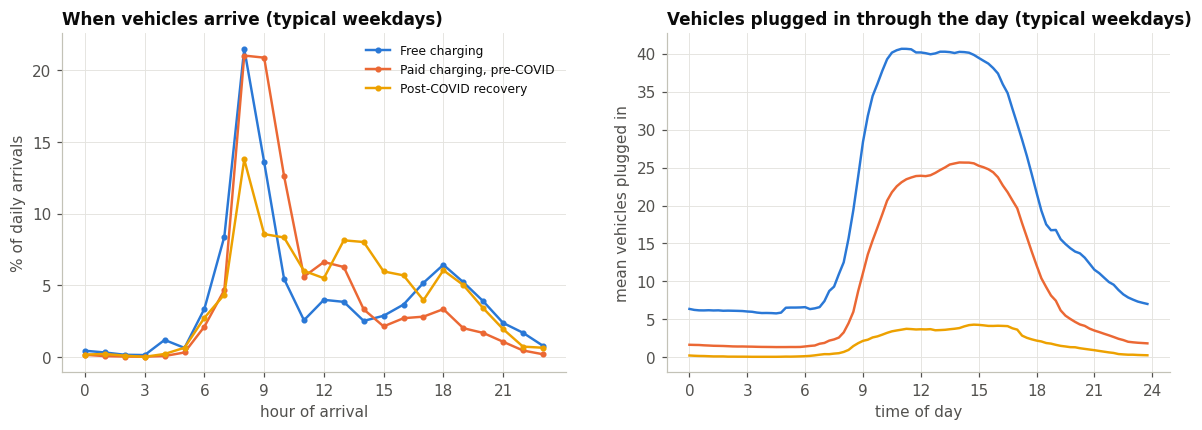

,regime,day_type,peak_arrival_hour,share_arrivals_06_10,share_arrivals_17_24,peak_plugged_in_time,mean_plugged_in_at_peak,busy_window_(>=90%_of_peak)
0,free,weekday,8,0.47,0.26,11:00,40.65,10:00-16:15
1,free,weekend,16,0.18,0.28,14:30,12.81,11:15-17:45
2,paid,weekday,8,0.49,0.11,14:00,25.67,11:15-16:15
3,paid,weekend,10,0.19,0.21,11:30,3.74,10:30-16:45
4,recovery,weekday,8,0.29,0.22,14:45,4.30,14:15-16:45
5,recovery,weekend,12,0.14,0.28,17:45,1.55,14:30-18:15


In [16]:
occ_df = occupancy.to_frame()
occ_df['date'] = occ_df.index.normalize()
occ_df = occ_df.join(daily[['regime', 'is_weekend', 'campus_closure', 'observed']], on='date')
occ_df['tod'] = occ_df.index.hour + occ_df.index.minute / 60
sess = sessions.join(daily[['regime', 'is_weekend', 'campus_closure']], on='date')
sess['hour'] = sess['start_local'].dt.hour

rows, profiles, arr_share = [], {}, {}
for name in MODEL_REGIMES:
    for wk_flag, lab in [(0, 'weekday'), (1, 'weekend')]:
        o = occ_df[(occ_df.regime == name) & (occ_df.is_weekend == wk_flag) & (occ_df.campus_closure == 0)]
        prof = o.groupby('tod')['plugged_in'].mean()
        s = sess[(sess.regime == name) & (sess.is_weekend == wk_flag) & (sess.campus_closure == 0)]
        share = s['hour'].value_counts(normalize=True).reindex(range(24), fill_value=0)
        profiles[(name, lab)], arr_share[(name, lab)] = prof, share
        hi = prof[prof >= 0.9 * prof.max()].index
        rows.append({'regime': name, 'day_type': lab, 'peak_arrival_hour': int(share.idxmax()),
                     'share_arrivals_06_10': share.loc[6:9].sum(), 'share_arrivals_17_24': share.loc[17:23].sum(),
                     'peak_plugged_in_time': hhmm(prof.idxmax()),
                     'mean_plugged_in_at_peak': prof.max(),
                     'busy_window_(>=90%_of_peak)': f'{hhmm(hi.min())}-{hhmm(hi.max() + 0.25)}'})
intraday = pd.DataFrame(rows)
save_table(intraday.round(3), '09_intraday_peaks', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in MODEL_REGIMES:
    axes[0].plot(range(24), 100 * arr_share[(name, 'weekday')], color=REGIME_COLORS[name],
                 marker='o', ms=3, label=REGIMES.loc[name, 'label'])
    p = profiles[(name, 'weekday')]
    axes[1].plot(p.index, p.values, color=REGIME_COLORS[name], label=REGIMES.loc[name, 'label'])
axes[0].set(title='When vehicles arrive (typical weekdays)', xlabel='hour of arrival', ylabel='% of daily arrivals',
            xticks=range(0, 24, 3))
axes[1].set(title='Vehicles plugged in through the day (typical weekdays)', xlabel='time of day',
            ylabel='mean vehicles plugged in', xticks=range(0, 25, 3))
axes[0].legend(fontsize=8)
save_fig(fig, 'T04_intraday_profiles')
intraday.round(2)

### 2.3 Weekly patterns

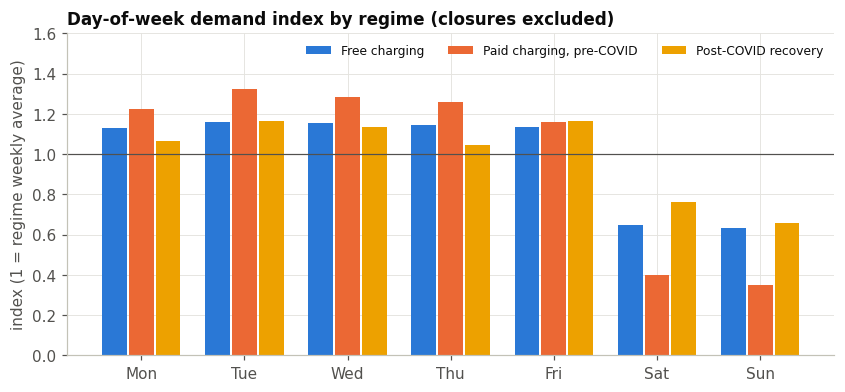

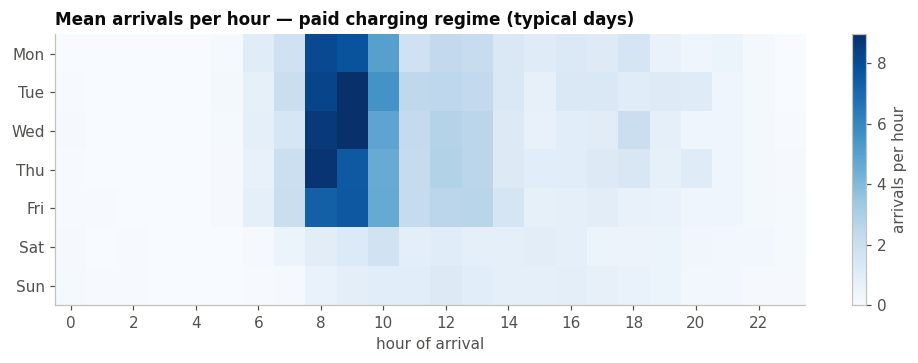

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
regime,,,,,,,
free,78.7,80.7,80.5,79.7,79.0,45.2,44.1
paid,38.1,41.3,40.0,39.3,36.2,12.4,10.8
recovery,12.1,13.2,12.9,11.8,13.2,8.7,7.5


In [17]:
dow_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
dow = (typical[typical.regime.isin(MODEL_REGIMES)]
       .groupby(['regime', 'dayofweek'])['session_count'].mean().unstack().reindex(MODEL_REGIMES))
dow.columns = dow_names
dow_index = dow.div(dow.mean(axis=1), axis=0)
save_table(dow.round(2), '10_day_of_week_mean')
save_table(dow_index.round(3), '10b_day_of_week_index')

fig, ax = plt.subplots(figsize=(9, 3.8))
w = 0.26
for i, name in enumerate(MODEL_REGIMES):
    ax.bar(np.arange(7) + (i - 1) * w, dow_index.loc[name], width=w - 0.02, color=REGIME_COLORS[name],
           label=REGIMES.loc[name, 'label'])
ax.axhline(1, color=INK2, lw=0.8)
ax.set_xticks(range(7), dow_names)
ax.set_ylabel('index (1 = regime weekly average)')
ax.set_ylim(0, 1.6)
ax.set_title('Day-of-week demand index by regime (closures excluded)')
ax.legend(fontsize=8, ncol=3, loc='upper right')
save_fig(fig, 'T05_day_of_week_index')

# Arrivals by weekday and hour, paid regime (the longest stable regime)
p = sess[(sess.regime == 'paid') & (sess.campus_closure == 0)]
n_days = typical[typical.regime == 'paid'].groupby('dayofweek').size()
heat = p.groupby([p['start_local'].dt.dayofweek, 'hour']).size().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
heat = heat.div(n_days, axis=0)
fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(heat.values, aspect='auto', cmap='Blues')
ax.set_yticks(range(7), dow_names); ax.set_xticks(range(0, 24, 2)); ax.grid(False)
ax.set_xlabel('hour of arrival'); ax.set_title('Mean arrivals per hour — paid charging regime (typical days)')
fig.colorbar(im, ax=ax, label='arrivals per hour')
save_fig(fig, 'T06_arrivals_weekday_hour_heatmap')
dow.round(1)

### 2.4 Peak-demand periods

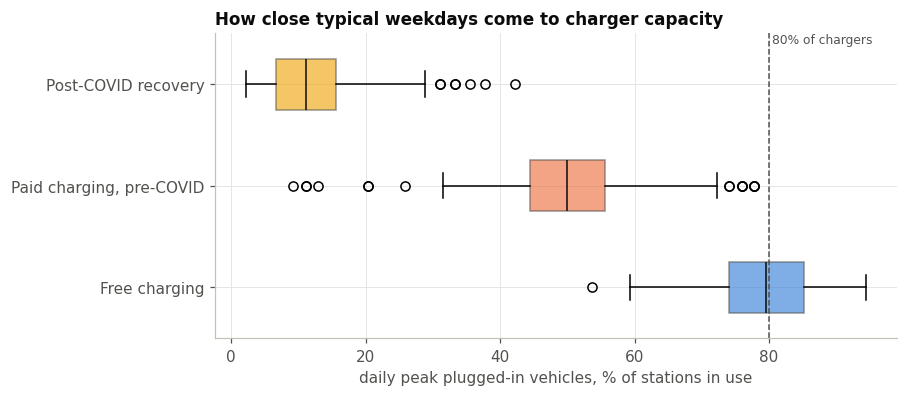

,stations_used,weekday_peak_median,weekday_peak_p95,weekday_peak_max,median_peak_utilisation,share_weekdays_peak_ge_80pct,busiest_weekday,busiest_hour
regime,,,,,,,,
free,54,43.0,48.0,51.0,0.80,0.46,Tue,8
paid,54,27.0,37.0,42.0,0.50,0.00,Tue,8
recovery,45,5.0,12.0,19.0,0.11,0.00,Fri,8


In [18]:
cap_rows = []
for name in MODEL_REGIMES:
    t = typical[(typical.regime == name) & (typical.is_weekend == 0)]
    n_st = int(reg_sum.at[name, 'stations_used'])
    util = t['peak_occupancy'] / n_st
    cap_rows.append({'regime': name, 'stations_used': n_st, 'weekday_peak_median': t.peak_occupancy.median(),
                     'weekday_peak_p95': t.peak_occupancy.quantile(0.95), 'weekday_peak_max': t.peak_occupancy.max(),
                     'median_peak_utilisation': util.median(), 'share_weekdays_peak_ge_80pct': (util >= 0.8).mean(),
                     'busiest_weekday': dow.loc[name].iloc[:5].idxmax(),
                     'busiest_hour': int(intraday.query('regime == @name and day_type == "weekday"')['peak_arrival_hour'].iloc[0])})
capacity = pd.DataFrame(cap_rows).set_index('regime')
save_table(capacity.round(3), '11_peak_capacity_pressure')

top_days = (d_obs[d_obs.regime.isin(MODEL_REGIMES)].sort_values('session_count', ascending=False)
            .groupby('regime', sort=False).head(5)[['regime', 'session_count', 'peak_occupancy', 'total_kWh']])
top_days['weekday'] = top_days.index.day_name().str[:3]
save_table(top_days, '11b_top_demand_days')

fig, ax = plt.subplots(figsize=(8, 3.6))
data = [100 * typical[(typical.regime == n) & (typical.is_weekend == 0)]['peak_occupancy'] / capacity.at[n, 'stations_used']
        for n in MODEL_REGIMES]
bp = ax.boxplot(data, vert=False, widths=0.5, patch_artist=True, medianprops={'color': INK})
for patch, n in zip(bp['boxes'], MODEL_REGIMES):
    patch.set(facecolor=REGIME_COLORS[n], alpha=0.6, edgecolor=INK2)
ax.set_yticks(range(1, 4), [REGIMES.loc[n, 'label'] for n in MODEL_REGIMES])
ax.axvline(80, color=INK2, ls='--', lw=1); ax.text(80.5, 3.4, '80% of chargers', fontsize=8, color=INK2)
ax.set_xlabel('daily peak plugged-in vehicles, % of stations in use')
ax.set_title('How close typical weekdays come to charger capacity')
save_fig(fig, 'T07_peak_occupancy_utilisation')
capacity.round(2)

### 2.5 Seasonality

Each regime is decomposed with robust STL (weekly period). The trend window is set to **43 days (about six weeks)** so that a one-week holiday dip does not bend the trend; with the default window (~11 days) the trend follows the closures and makes the normal days next to them look anomalous.

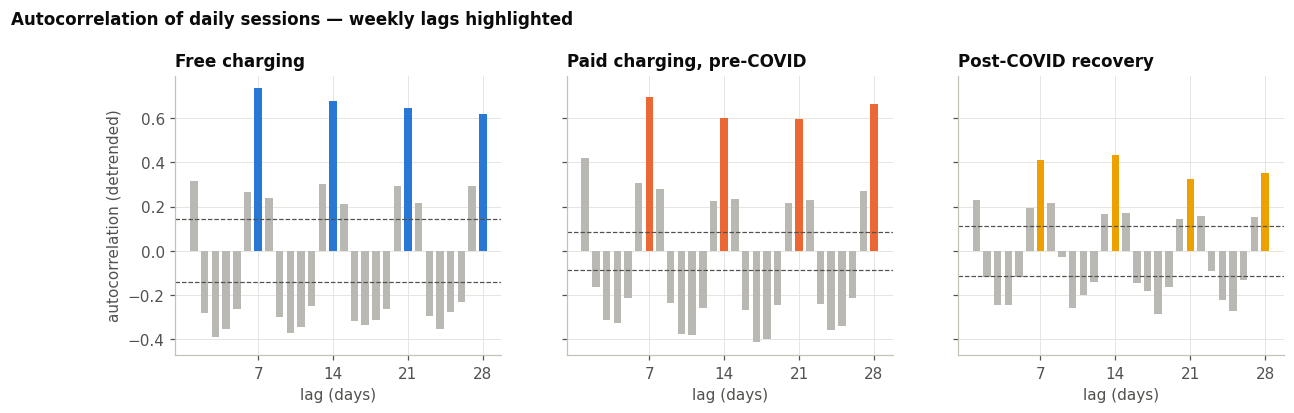

,acf_lag7,acf_lag14,acf_lag1,trend_strength,weekly_seasonal_strength
regime,,,,,
free,0.734,0.679,0.316,0.579,0.786
paid,0.694,0.603,0.418,0.298,0.685
recovery,0.411,0.432,0.229,0.779,0.576


In [19]:
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.seasonal import STL
warnings.simplefilter('ignore')     # statsmodels re-enables its own warnings on import

STL_TREND = 43

def stl_fit(name):
    s = d_obs.loc[d_obs.regime == name, 'session_count'].asfreq('D')
    return s, STL(s, period=7, trend=STL_TREND, robust=True).fit()

def strength(res):
    vr = np.var(res.resid)
    return (max(0, 1 - vr / np.var(res.trend + res.resid)), max(0, 1 - vr / np.var(res.seasonal + res.resid)))

season_rows, stl_res = [], {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, name in zip(axes, MODEL_REGIMES):
    s, res = stl_fit(name)
    stl_res[name] = (s, res)
    ac = acf(s - res.trend, nlags=28, fft=True)      # detrended, so the weekly cycle is not masked by level shifts
    ax.bar(range(1, 29), ac[1:], color=[REGIME_COLORS[name] if l % 7 == 0 else NEUTRAL for l in range(1, 29)], width=0.7)
    ax.axhline(1.96 / np.sqrt(len(s)), color=INK2, ls='--', lw=0.8); ax.axhline(-1.96 / np.sqrt(len(s)), color=INK2, ls='--', lw=0.8)
    ax.set(title=REGIMES.loc[name, 'label'], xlabel='lag (days)', xticks=[7, 14, 21, 28])
    ft, fs = strength(res)
    season_rows.append({'regime': name, 'acf_lag7': ac[7], 'acf_lag14': ac[14], 'acf_lag1': ac[1],
                        'trend_strength': ft, 'weekly_seasonal_strength': fs})
axes[0].set_ylabel('autocorrelation (detrended)')
fig.suptitle('Autocorrelation of daily sessions — weekly lags highlighted', x=0.01, y=1.06, ha='left', fontweight='bold', fontsize=11)
save_fig(fig, 'T08_acf_weekly_seasonality')
seasonality = save_table(pd.DataFrame(season_rows).set_index('regime').round(3), '12_seasonality_strength')
seasonality

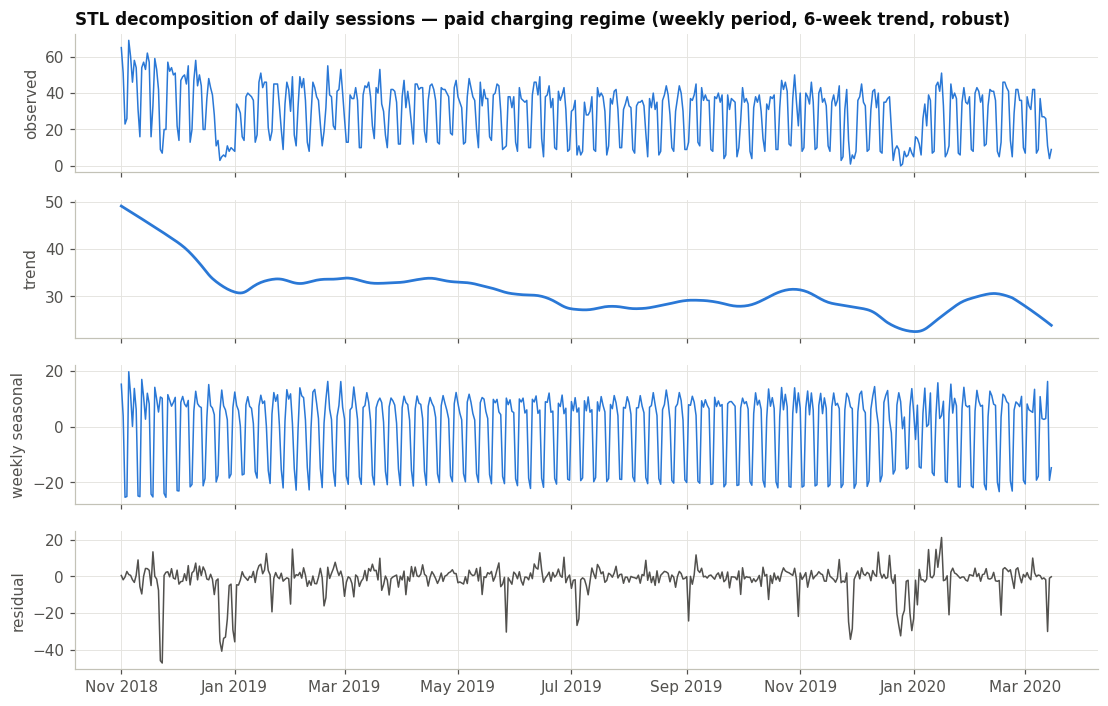

Summer (Jul-Aug 2019) vs rest of 2019, typical weekdays: -10.0%


,first year,second year,change
12,45.600,34.375,-0.246
1,39.905,35.571,-0.109
2,41.474,39.579,-0.046


In [20]:
s, res = stl_res['paid']
fig, axes = plt.subplots(4, 1, figsize=(12, 7.5), sharex=True)
for ax, (lab, ser) in zip(axes, [('observed', s), ('trend', res.trend), ('weekly seasonal', res.seasonal), ('residual', res.resid)]):
    ax.plot(ser.index, ser.values, color=SERIES if lab != 'residual' else INK2, lw=1.0 if lab != 'trend' else 1.8)
    ax.set_ylabel(lab)
axes[0].set_title('STL decomposition of daily sessions — paid charging regime (weekly period, 6-week trend, robust)')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
save_fig(fig, 'T09_stl_decomposition_paid')

# Annual pattern: only the paid regime spans more than a year. Complete months after the November 2018 adjustment.
pm = monthly[(monthly.regime == 'paid') & (monthly.month >= '2018-12-01') & (monthly.month <= '2020-02-01')].set_index('month')
pm['index_vs_regime_mean'] = pm['typical_weekday_sessions'] / pm['typical_weekday_sessions'].mean()
y19 = pm.loc['2019-01-01':'2019-12-01', 'typical_weekday_sessions']
summer = y19[y19.index.month.isin([7, 8])].mean() / y19[~y19.index.month.isin([7, 8])].mean() - 1
yoy = pd.DataFrame({m: [pm.loc[f'2018-{m:02d}-01' if m == 12 else f'2019-{m:02d}-01', 'typical_weekday_sessions'],
                        pm.loc[f'2019-{m:02d}-01' if m == 12 else f'2020-{m:02d}-01', 'typical_weekday_sessions']]
                    for m in [12, 1, 2]}, index=['first year', 'second year']).T
yoy['change'] = yoy['second year'] / yoy['first year'] - 1
save_table(pm.round(3), '12b_paid_monthly_index')
save_table(yoy.round(3), '12c_year_over_year')
print(f'Summer (Jul-Aug 2019) vs rest of 2019, typical weekdays: {summer:+.1%}')
yoy.round(3)

### 2.6 Unusual demand patterns and anomalies

A day is flagged when its STL residual is at least **4.5 robust standard deviations** (1.4826 × MAD) from the median residual of its regime. Each flagged day is then checked against the closure calendar.

Anomalous days (|robust z| >= 4.5): 48
likely_cause
campus closure       30
unexplained          15
next to a closure     3
COVID shock: 196 sessions/week in the 8 weeks before the shutdown -> 8.2 from April 2020 (-96%)


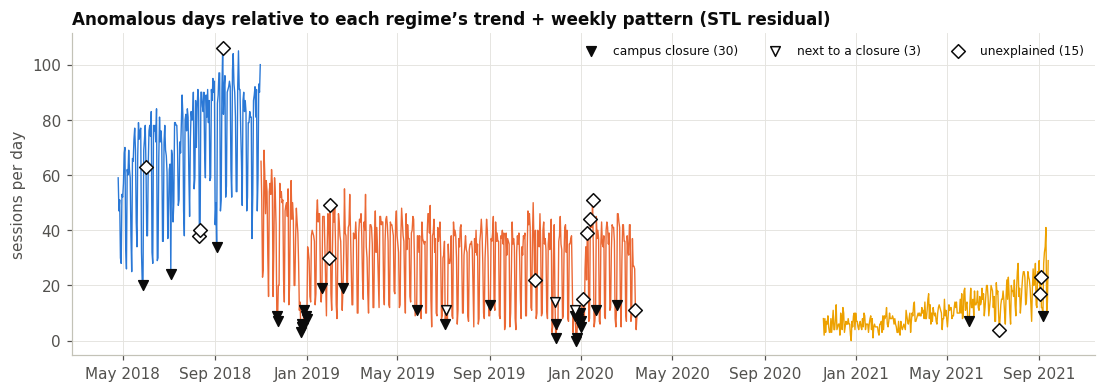

,date,weekday,regime,sessions,expected,robust_z,holiday,likely_cause
5,2018-09-03,Mon,free,34,90.5,-16.31,Labor Day,campus closure
8,2018-11-23,Fri,paid,7,53.9,-14.77,Day after Thanksgiving,campus closure
2,2018-07-04,Wed,free,24,74.1,-14.45,Independence Day,campus closure
7,2018-11-22,Thu,paid,9,54.7,-14.36,Thanksgiving Day,campus closure
0,2018-05-28,Mon,free,20,65.7,-13.17,Memorial Day,campus closure
10,2018-12-25,Tue,paid,5,45.5,-12.74,Christmas Day,campus closure
15,2019-01-01,Tue,paid,8,43.5,-11.14,New Year's Day,campus closure
9,2018-12-24,Mon,paid,3,38.1,-11.03,Winter break (24-31 Dec),campus closure
26,2019-11-28,Thu,paid,1,35.1,-10.71,Thanksgiving Day,campus closure
11,2018-12-26,Wed,paid,6,39.6,-10.54,Winter break (24-31 Dec),campus closure


In [21]:
ANOM_Z = 4.5
an_rows = []
for name in MODEL_REGIMES:
    s, res = stl_res[name]
    r = res.resid
    z = (r - r.median()) / (1.4826 * np.median(np.abs(r - r.median())))
    flag = z[np.abs(z) >= ANOM_Z]
    for d, zv in flag.items():
        near_closure = daily['campus_closure'].reindex(pd.date_range(d - pd.Timedelta(days=1), d + pd.Timedelta(days=1))).fillna(0).max()
        cause = ('campus closure' if daily.at[d, 'campus_closure'] else
                 'next to a closure' if near_closure else
                 'non-closure holiday' if pd.notna(daily.at[d, 'holiday_name']) else 'unexplained')
        an_rows.append({'date': d.date(), 'weekday': d.day_name()[:3], 'regime': name, 'sessions': int(s[d]),
                        'expected': round(float(res.trend[d] + res.seasonal[d]), 1), 'robust_z': round(float(zv), 2),
                        'holiday': daily.at[d, 'holiday_name'], 'likely_cause': cause})
anomalies = pd.DataFrame(an_rows).sort_values('robust_z')
save_table(anomalies, '13_anomalous_days', index=False)

pre = weekly[(weekly.index < REGIMES.at['covid', 'start']) & (weekly.index >= REGIMES.at['covid', 'start'] - pd.Timedelta(weeks=8))].mean()
lock = weekly[(weekly.index >= '2020-04-01') & (weekly.index <= REGIMES.at['covid', 'end'])].mean()
covid_drop = lock / pre - 1
print(f'Anomalous days (|robust z| >= {ANOM_Z}): {len(anomalies)}')
print(anomalies['likely_cause'].value_counts().to_string())
print(f'COVID shock: {pre:.0f} sessions/week in the 8 weeks before the shutdown -> {lock:.1f} from April 2020 ({covid_drop:.0%})')

fig, ax = plt.subplots(figsize=(12, 3.8))
for name in MODEL_REGIMES:
    s, res = stl_res[name]
    ax.plot(s.index, s.values, color=REGIME_COLORS[name], lw=0.9)
a = anomalies.assign(date=pd.to_datetime(anomalies['date']))
for cause, mk in [('campus closure', 'v'), ('next to a closure', 'v'), ('non-closure holiday', 'o'), ('unexplained', 'D')]:
    sel = a[a.likely_cause == cause]
    if len(sel):
        ax.scatter(sel['date'], sel['sessions'], marker=mk, s=40, facecolor='white' if cause != 'campus closure' else INK,
                   edgecolor=INK, zorder=3, label=f'{cause} ({len(sel)})')
ax.set_ylabel('sessions per day'); ax.legend(fontsize=8, ncol=4, loc='upper right')
ax.set_title('Anomalous days relative to each regime’s trend + weekly pattern (STL residual)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
save_fig(fig, 'T10_anomalous_days')
anomalies.head(15)

## 3. Forecasting

### 3.1 Choice of forecasting approach

What the analysis above says the model has to handle:

| Property of the series (§1–2) | Consequence for the method |
|---|---|
| Strong weekly cycle (ACF peaks at 7, 14, 21, 28) | needs a weekly seasonal component |
| Campus closures cut demand by most of a normal day | closure days must be an input known in advance, not something learnt from lags |
| Abrupt level shifts between regimes | train inside one regime only; the model must adapt its level quickly |
| Fewer than two years in any regime | annual seasonality cannot be estimated, so it is not modelled |
| Recovery regime is still growing | a trend (drift) term may be needed there |
| Counts of 5–100 per day | Gaussian errors on counts are acceptable; intervals clipped at 0 |

**Candidates.** Two baselines a planner would use without a model (*seasonal naive*: same weekday last week; *8-week weekday mean*, the rolling version of the Issue #13 baseline); *Holt-Winters* with damped trend and weekly seasonality (log scale); and three seasonal ARIMA variants: weekly *SARIMA*, *SARIMAX + closures* (closure indicator as exogenous regressor), and *SARIMAX + closures + drift*. SARIMA is the main candidate because it combines the weekly cycle, short-term autocorrelation, a known-in-advance regressor and proper prediction intervals in one model that can be fitted on a few hundred days. The machine-learning regressors of Issue #14 are not repeated: they were trained on the free-charging window and tested across the paid-charging break, which is exactly what the regime rule avoids.

**Validation design.** Rolling-origin backtest inside each regime that is long and stable enough: forecasts for the next **28 days** from 12 origins (every 2 weeks, Sep 2019 – Feb 2020) in the paid regime and 16 origins (weekly, May – Aug 2021) in the recovery regime. Each fit only sees data before its origin.

In [22]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.simplefilter('ignore')     # convergence is tracked explicitly in CONVERGED instead

ORDER, SEASONAL_ORDER = (1, 0, 1), (0, 1, 1, 7)
HORIZON = 28
CONVERGED = []                      # one entry per SARIMAX fit

def closure_exog(index):
    return pd.DataFrame({'campus_closure': index.isin(closure_calendar(index.min(), index.max()).index).astype(float)},
                        index=index)

def fit_forecast(model, train, future_index, alpha=0.2, return_fit=False):
    # Returns a frame with forecast and (where the model provides them) prediction intervals, clipped at 0
    train = train.asfreq('D')
    h = len(future_index)
    out = pd.DataFrame(index=future_index)
    fit = None
    if model == 'Seasonal naive':
        out['forecast'] = np.resize(train.values[-7:], h)
    elif model == '8-week weekday mean':
        last = train.iloc[-56:]
        out['forecast'] = last.groupby(last.index.dayofweek).mean().reindex(future_index.dayofweek).values
    elif model == 'Holt-Winters (damped, log)':
        fit = ExponentialSmoothing(np.log1p(train), trend='add', damped_trend=True, seasonal='add',
                                   seasonal_periods=7, initialization_method='estimated').fit()
        out['forecast'] = np.expm1(fit.forecast(h).values)
    else:
        use_exog = 'closures' in model
        fit = SARIMAX(train, exog=closure_exog(train.index) if use_exog else None, order=ORDER,
                      seasonal_order=SEASONAL_ORDER, trend='c' if 'drift' in model else 'n').fit(disp=False)
        CONVERGED.append(bool(fit.mle_retvals.get('converged', True)))
        fc = fit.get_forecast(h, exog=closure_exog(future_index) if use_exog else None)
        out['forecast'] = fc.predicted_mean.values
        for a_, tag in [(alpha, '80' if alpha == 0.2 else str(int(100 * (1 - alpha)))), (0.05, '95')]:
            ci = fc.conf_int(alpha=a_)
            out[f'lo{tag}'], out[f'hi{tag}'] = ci.iloc[:, 0].values, ci.iloc[:, 1].values
    out = out.clip(lower=0)
    return (out, fit) if return_fit else out

MODELS = ['Seasonal naive', '8-week weekday mean', 'Holt-Winters (damped, log)',
          'SARIMA (weekly)', 'SARIMAX + closures', 'SARIMAX + closures + drift']
BACKTEST_ORIGINS = {'paid': pd.date_range('2019-09-02', '2020-02-09', freq='14D'),
                    'recovery': pd.date_range('2021-05-03', '2021-08-16', freq='7D')}
print({k: (v[0].date(), v[-1].date(), len(v)) for k, v in BACKTEST_ORIGINS.items()})

{'paid': (datetime.date(2019, 9, 2), datetime.date(2020, 2, 3), 12), 'recovery': (datetime.date(2021, 5, 3), datetime.date(2021, 8, 16), 16)}


### 3.2 Rolling-origin backtest

In [23]:
bt_rows, bt_preds = [], []
for regime, origins in BACKTEST_ORIGINS.items():
    series = d_obs.loc[d_obs.regime == regime, 'session_count']
    for model in MODELS:
        parts = []
        for o in origins:
            train = series[:o - pd.Timedelta(days=1)]
            test = series[o:o + pd.Timedelta(days=HORIZON - 1)]
            f = fit_forecast(model, train, test.index)
            f['actual'], f['origin'], f['h'] = test.values, o, np.arange(1, len(test) + 1)
            parts.append(f)
        e = pd.concat(parts)
        err = e['actual'] - e['forecast']
        cl = e.index.isin(closures.index)
        bt_rows.append({'regime': regime, 'model': model, 'MAE': err.abs().mean(), 'RMSE': np.sqrt((err ** 2).mean()),
                        'WAPE': err.abs().sum() / e['actual'].sum(), 'bias_actual_minus_forecast': err.mean(),
                        'MAE_closure_days': err[cl].abs().mean(), 'MAE_other_days': err[~cl].abs().mean(),
                        'coverage_80': ((e['actual'] >= e['lo80']) & (e['actual'] <= e['hi80'])).mean() if 'lo80' in e else np.nan,
                        'forecasts': len(e)})
        bt_preds.append(e.assign(regime=regime, model=model))
backtest = pd.DataFrame(bt_rows)
backtest.round(4).to_csv(ROOT / 'ts_backtest_i16.csv', index=False)
print(f'SARIMAX fits in the backtest: {len(CONVERGED)}; the optimiser stopped before full convergence in '
      f'{CONVERGED.count(False)} of them (their forecasts are kept as returned)')
backtest.round(3)

SARIMAX fits in the backtest: 84; the optimiser stopped before full convergence in 5 of them (their forecasts are kept as returned)


,regime,model,MAE,RMSE,WAPE,bias_actual_minus_forecast,MAE_closure_days,MAE_other_days,coverage_80,forecasts
0,paid,Seasonal naive,7.973,12.279,0.302,-1.170,25.346,6.516,NaN,336
1,paid,8-week weekday mean,6.821,10.311,0.258,-0.199,24.409,5.346,NaN,336
2,paid,"Holt-Winters (damped, log)",7.669,10.631,0.290,0.807,20.810,6.567,NaN,336
3,paid,SARIMA (weekly),6.208,9.737,0.235,-2.018,25.129,4.621,0.887,336
4,paid,SARIMAX + closures,4.447,6.103,0.168,0.321,3.988,4.486,0.875,336
5,paid,SARIMAX + closures + drift,4.936,6.577,0.187,2.319,4.097,5.006,0.807,336
6,recovery,Seasonal naive,3.810,4.864,0.247,1.480,6.778,3.749,NaN,448
7,recovery,8-week weekday mean,3.863,4.929,0.250,3.059,4.069,3.859,NaN,448
8,recovery,"Holt-Winters (damped, log)",3.547,4.502,0.230,1.852,7.461,3.466,NaN,448
9,recovery,SARIMA (weekly),3.469,4.442,0.225,1.742,6.382,3.409,0.643,448


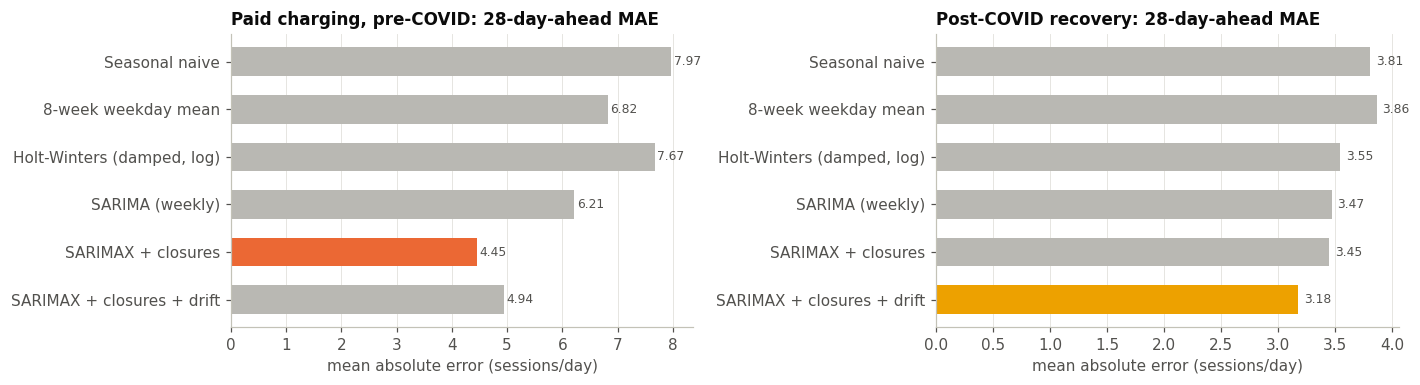

AIC          backtest_MAE         
regime                       paid recovery         paid recovery
order     seasonal_order                                        
(1, 0, 0) (0, 1, 1, 7)    3232.66  1576.61         4.52     3.57
(1, 0, 1) (0, 1, 1, 7)    3219.83  1550.89         4.45     3.45
          (1, 1, 1, 7)    3222.34  1548.40         4.43     3.44
(1, 1, 1) (0, 1, 1, 7)    3204.44  1548.44         4.43     3.24
(2, 0, 1) (0, 1, 1, 7)    3207.02  1551.94         4.37     3.46

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, regime in zip(axes, BACKTEST_ORIGINS):
    b = backtest[backtest.regime == regime].set_index('model').loc[MODELS[::-1]]
    best = b['MAE'].idxmin()
    ax.barh(b.index, b['MAE'], color=[REGIME_COLORS[regime] if m == best else NEUTRAL for m in b.index], height=0.6)
    for i, v in enumerate(b['MAE']):
        ax.text(v + 0.05, i, f'{v:.2f}', va='center', fontsize=8, color=INK2)
    ax.set(title=f'{REGIMES.loc[regime, "label"]}: 28-day-ahead MAE', xlabel='mean absolute error (sessions/day)')
    ax.grid(axis='y', visible=False)
fig.tight_layout()
save_fig(fig, 'T11_backtest_mae')

# Order check (closure regressor, no drift): in-sample AIC on the whole regime and the same 28-day backtest
order_rows = []
for regime, origins in BACKTEST_ORIGINS.items():
    series = d_obs.loc[d_obs.regime == regime, 'session_count'].asfreq('D')
    for o, so in [((1, 0, 1), (0, 1, 1, 7)), ((1, 1, 1), (0, 1, 1, 7)), ((2, 0, 1), (0, 1, 1, 7)),
                  ((1, 0, 0), (0, 1, 1, 7)), ((1, 0, 1), (1, 1, 1, 7))]:
        f = SARIMAX(series, exog=closure_exog(series.index), order=o, seasonal_order=so).fit(disp=False)
        errs = []
        for org in origins:
            tr, te = series[:org - pd.Timedelta(days=1)], series[org:org + pd.Timedelta(days=HORIZON - 1)]
            ff = SARIMAX(tr, exog=closure_exog(tr.index), order=o, seasonal_order=so).fit(disp=False)
            errs.append(np.abs(te.values - ff.forecast(len(te), exog=closure_exog(te.index)).clip(lower=0).values))
        order_rows.append({'regime': regime, 'order': str(o), 'seasonal_order': str(so), 'AIC': f.aic, 'BIC': f.bic,
                           'backtest_MAE': np.concatenate(errs).mean()})
orders = save_table(pd.DataFrame(order_rows).round(3), '14_sarimax_order_check', index=False)
orders.pivot(index=['order', 'seasonal_order'], columns='regime', values=['AIC', 'backtest_MAE']).round(2)

In [25]:
best = backtest.loc[backtest.groupby('regime')['MAE'].idxmin()].set_index('regime')
BEST = best['model'].to_dict()
FORECAST_MODEL = BEST['recovery']          # the future forecast starts from the recovery regime
ref = backtest.set_index(['regime', 'model'])
gain = {r: 1 - best.at[r, 'MAE'] / ref.loc[(r, '8-week weekday mean'), 'MAE'] for r in BEST}
excl_gain = 1 - ref.loc[('paid', 'SARIMAX + closures'), 'MAE'] / ref.loc[('paid', 'SARIMA (weekly)'), 'MAE']
sel = dict(best_paid=BEST['paid'], mae_paid=best.at['paid', 'MAE'], gain_paid=gain['paid'],
           best_rec=BEST['recovery'], mae_rec=best.at['recovery', 'MAE'], gain_rec=gain['recovery'],
           excl_gain=excl_gain, order=ORDER, sorder=SEASONAL_ORDER[:3], fmodel=FORECAST_MODEL,
           drift_rec='a drift term' if 'drift' in BEST['recovery'] else 'no drift term',
           drift_paid='it does too' if 'drift' in BEST['paid'] else 'drift makes forecasts worse')
chosen = orders[(orders.order == str(ORDER)) & (orders.seasonal_order == str(SEASONAL_ORDER))].set_index('regime')
order_txt = []
for r in BACKTEST_ORIGINS:
    o_r = orders[orders.regime == r]
    alt = o_r.loc[o_r['backtest_MAE'].idxmin()]
    order_txt.append('{}: backtest MAE {:.2f} vs {:.2f} for the best alternative {}×{}, ΔAIC {:+.1f} against the lowest-AIC order'
                     .format(REGIMES.at[r, 'label'], chosen.at[r, 'backtest_MAE'], alt['backtest_MAE'], alt['order'],
                             alt['seasonal_order'], chosen.at[r, 'AIC'] - o_r['AIC'].min()))
sel['order_txt'] = '; '.join(order_txt)
sel['order_gap'] = max(chosen.at[r, 'backtest_MAE'] - orders[orders.regime == r]['backtest_MAE'].min() for r in BACKTEST_ORIGINS)
rec_min_order = orders[orders.regime == 'recovery']['backtest_MAE'].min()
sel['drift_vs_orders'] = (' With its drift term, the selected recovery model (MAE {:.2f}) beats every order tried without one.'
                          .format(best.at['recovery', 'MAE']) if best.at['recovery', 'MAE'] < rec_min_order else '')
display(Markdown("""
**Selected approach.** Best model by 28-day MAE: **{best_paid}** in the paid regime
(MAE {mae_paid:.2f}, {gain_paid:.0%} below the 8-week weekday mean) and **{best_rec}** in the
recovery regime (MAE {mae_rec:.2f}, {gain_rec:.0%} below the same baseline).

- The closure regressor is what makes SARIMA useful: adding it lowers paid-regime MAE by {excl_gain:.0%} relative to
  plain weekly SARIMA, because holiday weeks are where the largest errors occur.
- The drift term only pays off where demand is still growing: in the recovery regime the best model includes
  {drift_rec}; in the stable paid regime {drift_paid}. The trend term is therefore chosen by
  backtest inside the regime the forecast is made from.
- Orders: SARIMA{order}×{sorder}₇ is used for every variant. Order check ({order_txt}). Out of sample the shared
  order is at most {order_gap:.2f} sessions/day worse than the best alternative in either regime, so one specification is
  kept for both regimes; out-of-sample error, not in-sample AIC, is the selection criterion because the model is used
  to forecast.{drift_vs_orders}
- **Model used for the future forecast: {fmodel}**, fitted on the recovery regime (the current state of
  demand at the end of the data).""".format(**sel)))


**Selected approach.** Best model by 28-day MAE: **SARIMAX + closures** in the paid regime
(MAE 4.45, 35% below the 8-week weekday mean) and **SARIMAX + closures + drift** in the
recovery regime (MAE 3.18, 18% below the same baseline).

- The closure regressor is what makes SARIMA useful: adding it lowers paid-regime MAE by 28% relative to
  plain weekly SARIMA, because holiday weeks are where the largest errors occur.
- The drift term only pays off where demand is still growing: in the recovery regime the best model includes
  a drift term; in the stable paid regime drift makes forecasts worse. The trend term is therefore chosen by
  backtest inside the regime the forecast is made from.
- Orders: SARIMA(1, 0, 1)×(0, 1, 1)₇ is used for every variant. Order check (Paid charging, pre-COVID: backtest MAE 4.45 vs 4.37 for the best alternative (2, 0, 1)×(0, 1, 1, 7), ΔAIC +15.4 against the lowest-AIC order; Post-COVID recovery: backtest MAE 3.45 vs 3.25 for the best alternative (1, 1, 1)×(0, 1, 1, 7), ΔAIC +2.5 against the lowest-AIC order). Out of sample the shared
  order is at most 0.20 sessions/day worse than the best alternative in either regime, so one specification is
  kept for both regimes; out-of-sample error, not in-sample AIC, is the selection criterion because the model is used
  to forecast. With its drift term, the selected recovery model (MAE 3.18) beats every order tried without one.
- **Model used for the future forecast: SARIMAX + closures + drift**, fitted on the recovery regime (the current state of
  demand at the end of the data).